<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>🚴‍♀️Bike Sharing EDA📈 & Regression Model Predict💡</b></div>

![](https://cdn.dribbble.com/users/187497/screenshots/3063127/arc-bike2.gif)

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>Introduction</b></div>
<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
Sharing bikes, also known as bike-sharing or bikesharing,<br> is a service that allows people to rent bikes for a short period of time, usually by the hour or day, for a fee. <br>The bikes can be picked up and dropped off at designated locations and are often equipped with GPS tracking and other technology.<br>The aim of sharing bikes is to provide an alternative mode of transportation, <br>reduce traffic congestion and carbon emissions, and promote a healthy lifestyle.
    <br>
    <br>
    In this notebook, we conducted a graph and exploratory data analysis on the relationship between total loans in various aspects such as date, time, temperature, and wind speed for bicycle sharing demand in 2011 and 2012. After that, the test values were predicted through machine learning's random forest regression model and deep learning regression model, and the two data were merged to generate new predictions, obtaining a total of three predictions, and comparing the accuracy.

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>Columns</b></div>
<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
Introduction<br>
Import Libraries<br>
Check Missing Value<br>
Visuallization<br>
Season,Temp,Atemp<br>
Datetime<br>
Workingday,Holiday - by time<br>
Humidity<br>
WindSpeed<br>
Preparing Test Data<br>
Machine Learning<br>
Compare ML Score Visuallization<br>
Submission</div>

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>Table of Contents</b></div>
<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
<b><mark>datetime</mark></b><br>  hourly date + timestamp  <br>
<b><mark>season</mark></b><br>   1 = spring, 2 = summer, 3 = fall, 4 = winter <br>
<b><mark>holiday</mark></b><br> - whether the day is considered a holiday<br>
<b><mark>workingday</mark></b><br> - whether the day is neither a weekend nor holiday<br>
<b><mark>weather</mark></b> - <br>
    1: Clear, Few clouds, Partly cloudy, Partly cloudy<br>
2: Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist<br>
3: Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds<br>
4: Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog <br>
<b><mark>temp</mark></b><br> - temperature in Celsius<br>
<b><mark>atemp</mark></b><br> - "feels like" temperature in Celsius<br>
<b><mark>humidity</mark></b><br> - relative humidity<br>
<b><mark>windspeed</mark></b><br> - wind speed<br>
<b><mark>casual</mark></b><br> - number of non-registered user rentals initiated<br>
<b><mark>registered</mark></b><br> - number of registered user rentals initiated<br>
<b><mark>count</mark></b><br> - number of total rentals</div>

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>0. Import Libraries</b></div>

In [1]:
# Data
import pandas as pd
import numpy as np
import missingno as msno

# Visuallization
import matplotlib.pyplot as plt
import seaborn as sns

# Deep Learning
import tensorflow as tf
from tensorflow import compat

# Machine Learning
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

In [2]:
train = pd.read_csv("/kaggle/input/bike-sharing-demand/train.csv")
test = pd.read_csv("/kaggle/input/bike-sharing-demand/test.csv")
train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


In [3]:
test.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed
0,2011-01-20 00:00:00,1,0,1,1,10.66,11.365,56,26.0027
1,2011-01-20 01:00:00,1,0,1,1,10.66,13.635,56,0.0000
2,2011-01-20 02:00:00,1,0,1,1,10.66,13.635,56,0.0000
3,2011-01-20 03:00:00,1,0,1,1,10.66,12.880,56,11.0014
4,2011-01-20 04:00:00,1,0,1,1,10.66,12.880,56,11.0014


<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>1. Check Missing Value</b></div>

<AxesSubplot:>

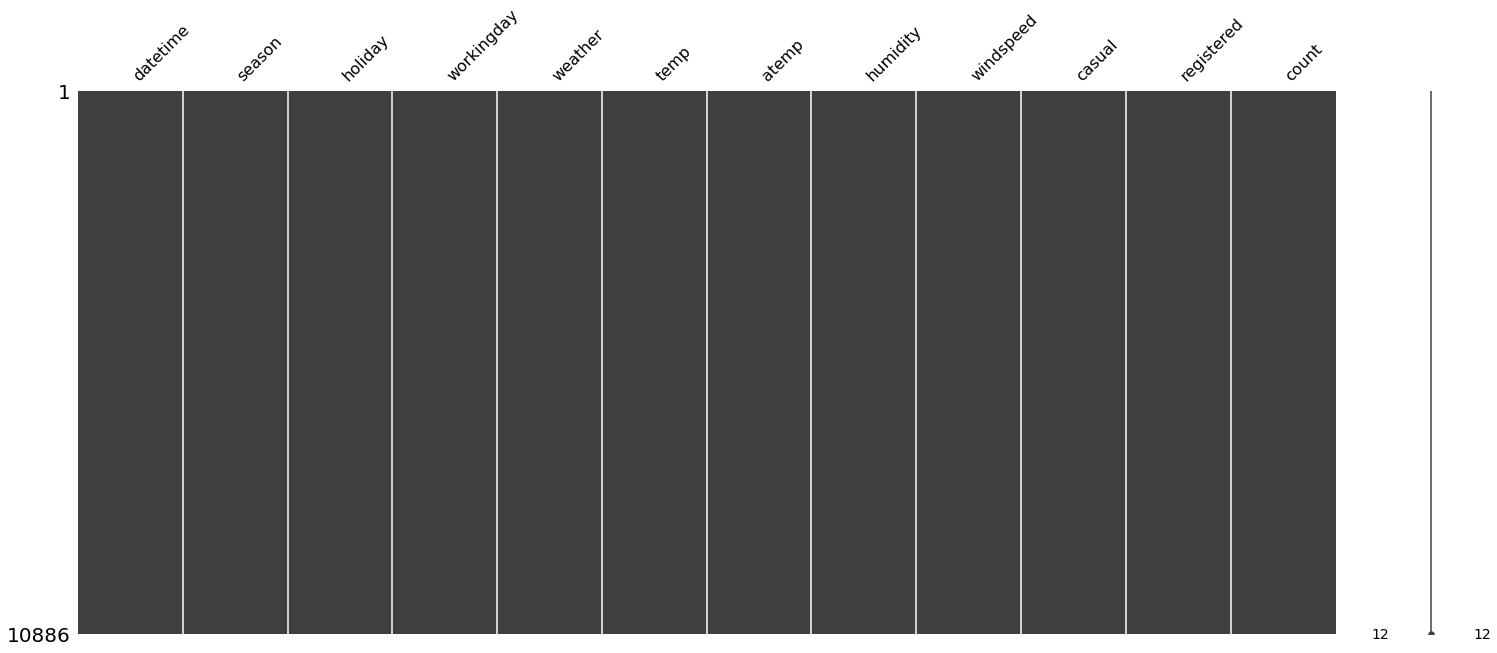

In [4]:
msno.matrix(train)

<AxesSubplot:>

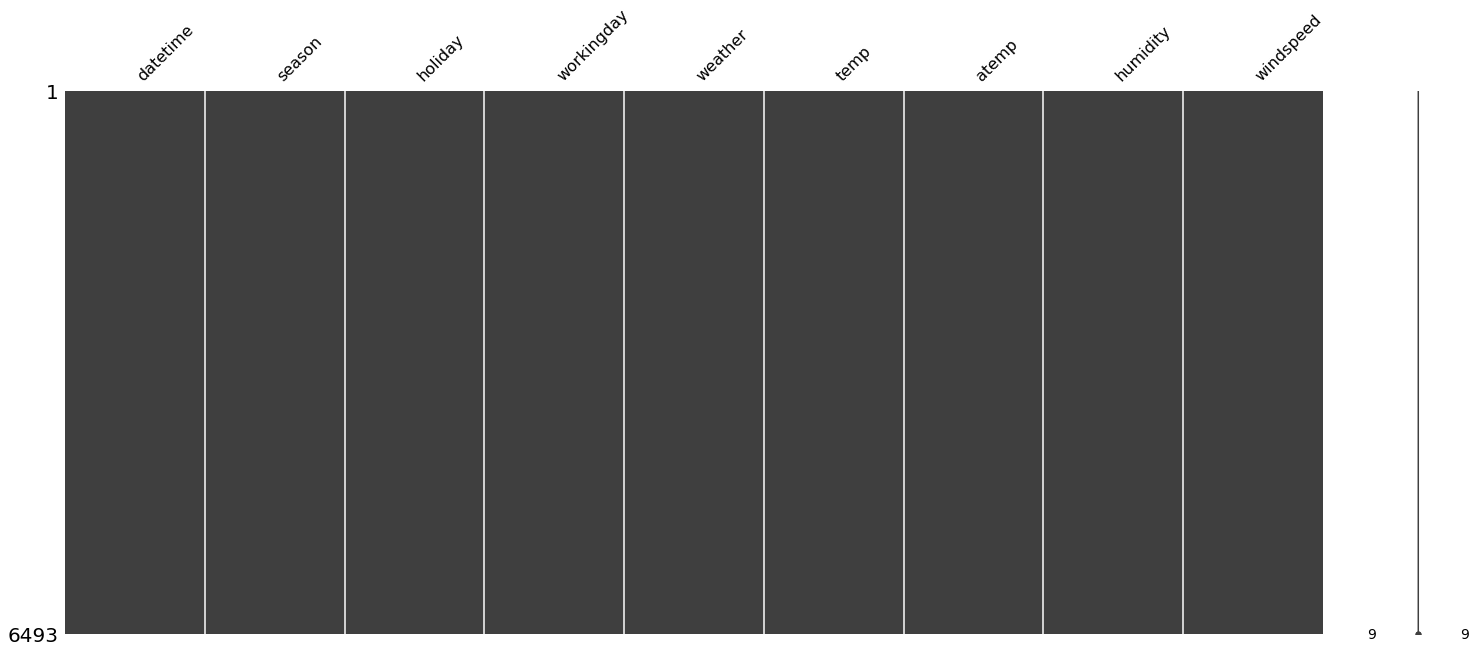

In [5]:
msno.matrix(test)

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>2. Visuallization</b></div>


In [6]:
train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1


<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>2.1 Season,Temp,Atemp</b></div>

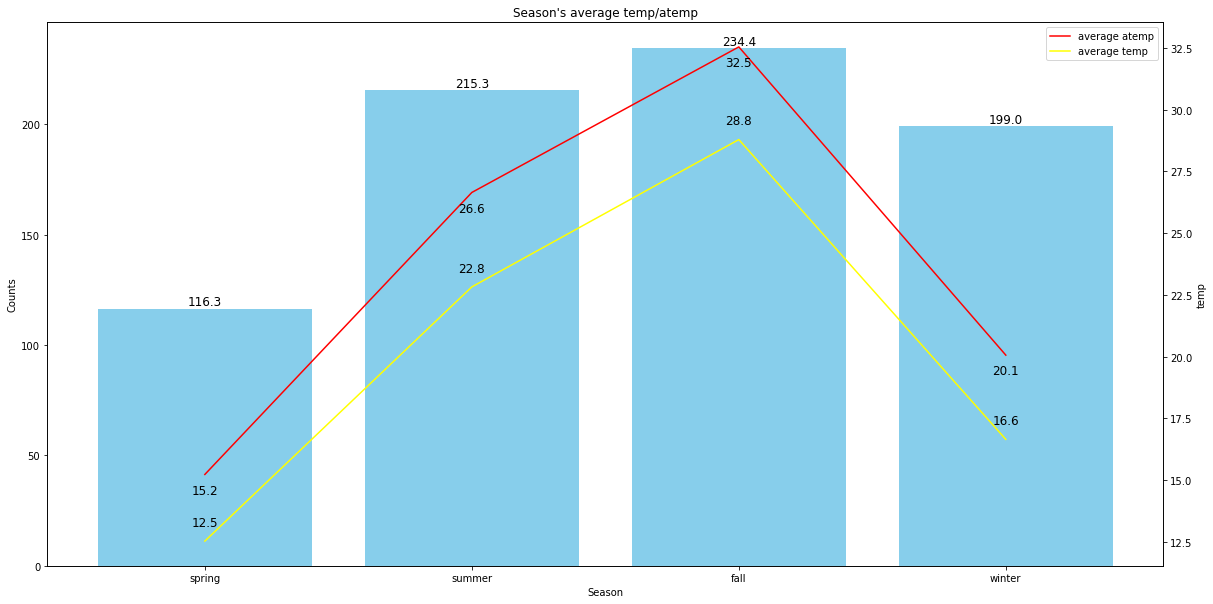

In [7]:

x = ["spring","summer","fall","winter"]
y , y1, y2 = [],[],[]
for i in range(1,5):
    y.append(np.mean(train[train["season"]==i]["temp"].values.tolist()))
    y1.append(np.mean(train[train["season"]==i]["atemp"].values.tolist()))
    y2.append(np.mean(train[train["season"]==i]["count"].values.tolist()))

plt.figure(figsize=(20,10))

for i in range(len(x)): # season counts visualize
    height = y2[i]
    plt.text(x[i], height + 0.25, '%.1f' %height, ha='center', va='bottom', size = 12)
plt.title("Season's average temp/atemp")
plt.xlabel("Season")
plt.ylabel("Counts")
plt.bar(x,y2,color="skyblue",label="count")

ay1 = plt.twinx()
for i in range(len(x)): # average temp numb visualize
    height = y[i]
    plt.text(x[i], height + 0.5, '%.1f' %height, ha='center', va='bottom', size = 12)
    
for i in range(len(x)):# average atemp numb visualize
    height = y1[i]
    plt.text(x[i], height  -0.9, '%.1f' %height, ha='center', va='bottom', size = 12)
ay1.plot(x,y1,color="red",label="average atemp")
ay1.plot(x,y,color='yellow',label="average temp")
plt.ylabel("temp")
plt.legend()

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">

<b>Describe</b><br>
    The temperature changes a lot with the seasons. In other words, weather and temperature have a direct relationship, and the graph above is the result of visualizing the relationship between the two factors and the analysis of how much the seasonal (average temperature by season) bicycle loan exists.<br> As you can see from the graph, when summer is coming to an end in autumn and winter is coming, the weather is considered the warmest and most suitable day, and when that happens, the most utilization rate is recorded.

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>2.2 Datetime</b></div>

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
<b>Split datetime info</b><br>
In this session, it may be seen that the year, month, and day information are recorded together in one row in the data. <br>For visualization and more efficient learning modeling, I decided to divide it into three columns: year, month, and day. 

In [8]:
year = []
month = []
day = []
time = []
for i in range(len(train)):
    year.append(int(train["datetime"].values[i].split()[0].split("-")[0]))
    month.append(int(train["datetime"].values[i].split()[0].split("-")[1]))
    day.append(int(train["datetime"].values[i].split()[0].split("-")[2]))
    time.append(int(train["datetime"].values[i].split()[1].split(":")[0]))
train["year"] = year
train["month"] = month
train["day"] = day
train["time"] = time

In [9]:
year = []
month = []
day = []
time = []
for i in range(len(test)):
    year.append(int(test["datetime"].values[i].split()[0].split("-")[0]))
    month.append(int(test["datetime"].values[i].split()[0].split("-")[1]))
    day.append(int(test["datetime"].values[i].split()[0].split("-")[2]))
    time.append(int(test["datetime"].values[i].split()[1].split(":")[0]))
test["year"] = year
test["month"] = month
test["day"] = day
test["time"] = time

In [10]:
train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,time
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,81,0.0,3,13,16,2011,1,1,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,80,0.0,8,32,40,2011,1,1,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,80,0.0,5,27,32,2011,1,1,2
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,75,0.0,3,10,13,2011,1,1,3
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,75,0.0,0,1,1,2011,1,1,4


In [11]:
test.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,year,month,day,time
0,2011-01-20 00:00:00,1,0,1,1,10.66,11.365,56,26.0027,2011,1,20,0
1,2011-01-20 01:00:00,1,0,1,1,10.66,13.635,56,0.0000,2011,1,20,1
2,2011-01-20 02:00:00,1,0,1,1,10.66,13.635,56,0.0000,2011,1,20,2
3,2011-01-20 03:00:00,1,0,1,1,10.66,12.880,56,11.0014,2011,1,20,3
4,2011-01-20 04:00:00,1,0,1,1,10.66,12.880,56,11.0014,2011,1,20,4


<a id="1"></a>
## <div style="text-align:center; padding:10px;color:white;margin:0;font-size:30px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>per year's count</b></div>

In [12]:
train["year"].value_counts().values[0]

5464

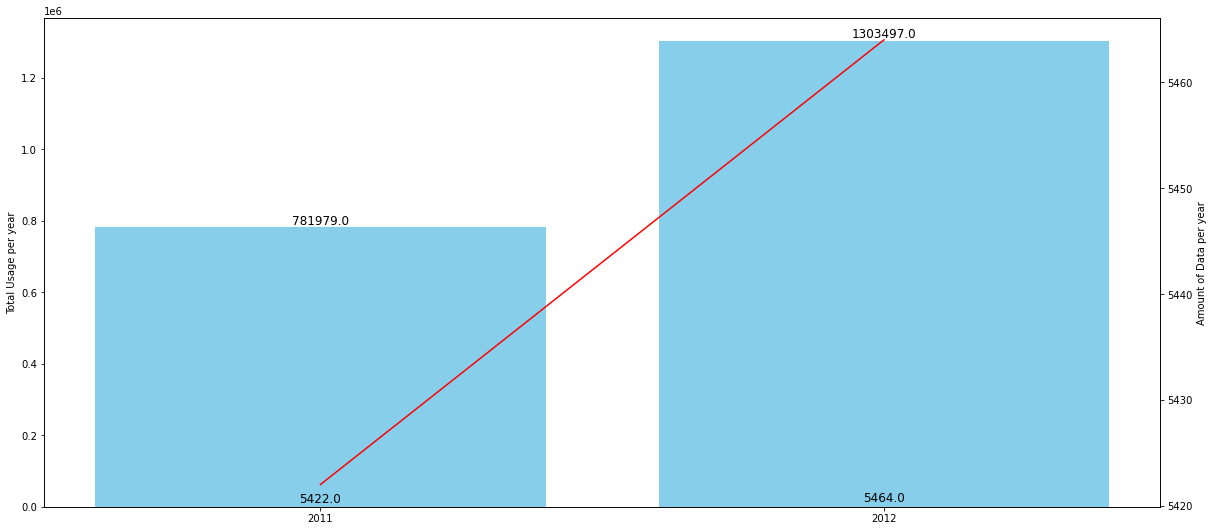

In [13]:
y = [train[train["year"]==2011]["count"].sum(),
     train[train["year"]==2012]["count"].sum()]
x = ["2011","2012"]
y1 = [train["year"].value_counts().values[1],
      train["year"].value_counts().values[0]]
plt.figure(figsize=(20,9))


for i in range(len(x)):
    height = y[i]
    plt.text(x[i], height + 1.9, '%.1f' %height, ha='center', va='bottom', size = 12)
for i in range(len(x)):
    height = y1[i]
    plt.text(x[i], height  -0.9, '%.1f' %height, ha='center', va='bottom', size = 12)
    

plt.bar(x,y,color="skyblue")
plt.ylabel("Total Usage per year")
ax = plt.twinx()
plt.ylabel("Amount of Data per year")
ax.plot(x,y1,color="red")

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">

<b>Describe</b><br>
 The number of data in 2011 and 2012 has approximately 1.07 times(7%) the amount of data. <br>However, it is confirmed that the usage rate of bicycle rental increased by about 66% from 781979 in 2011 to 1303497 in 2012. 

<a id="1"></a>
## <div style="text-align:center; padding:10px;color:white;margin:0;font-size:30px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>per month's counts
</b></div>

<BarContainer object of 12 artists>

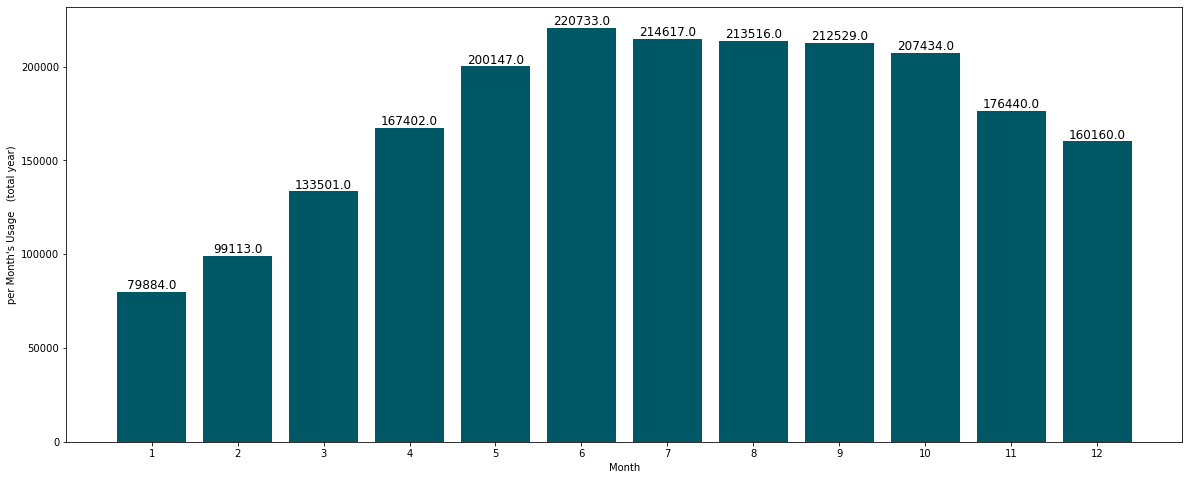

In [14]:
x = ["1","2","3","4","5","6","7","8","9","10","11","12"]
y = []
for i in range(1,13):
    y.append(train[train["month"]==i]["count"].sum())
plt.figure(figsize=(20,8))
for i in range(len(x)):
    height = y[i]
    plt.text(x[i], height + 1.9, '%.1f' %height, ha='center', va='bottom', size = 12)
plt.title("")
plt.xlabel("Month")
plt.ylabel("per Month's Usage   (total year)")
plt.bar(x,y,color = '#005766')

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">

<b>Describe</b><br>
As in the previous seasonal demand analysis, when comparing monthly demand, it is confirmed that the amount of loans during the fall period is the highest, and among them, the amount of loans during the period between summer and autumn is the highest.

<a id="1"></a>
## <div style="text-align:center; padding:10px;color:white;margin:0;font-size:30px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>per time's counts
</b></div>

In [15]:
for i in range(24):
    y.append(train[train["time"]==i]["count"].sum())

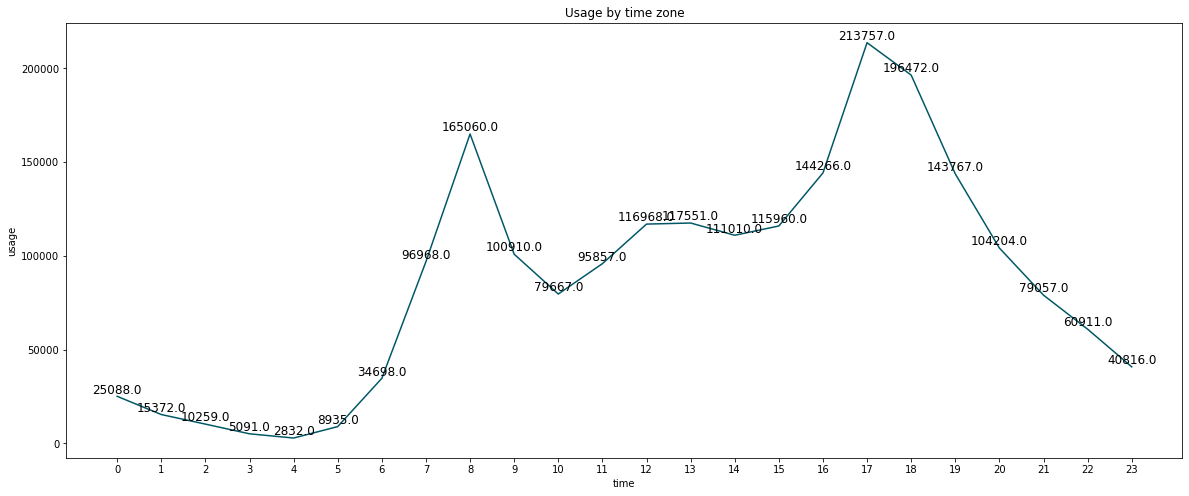

In [16]:
x = []
for i in range(24):
    x.append(str(i))
y = []
for i in range(24):
    y.append(train[train["time"]==i]["count"].sum())
plt.figure(figsize=(20,8))
for i in range(len(x)):
    height = y[i]
    plt.text(x[i], height + 1.9, '%.1f' %height, ha='center', va='bottom', size = 12)
plt.title("Usage by time zone")
plt.xlabel("time")
plt.ylabel("usage")
plt.plot(x,y,color = '#005766')

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">

<b>Describe</b><br>
 Through the graph above, the usage is high from 7a.m -9 a.m. and 4 p.m -7 p.m.<br>
 It can be predicted that this situation is usually rented during rush hour and rush hour. If so, the elements of the holiday may also have a significant correlation with the results. First of all, I would like to analyze the correlation between the two through data macroization.

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>2.3 Workingday, Holiday - by time</b></div>

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">

<b>Through the above time-by-hour analysis, the question was raised as to whether it was related to working days, holidays, and time zones for bicycle demand. <br>Since the data contained data on working days and holidays, I would like to use this data to determine the reason for demand more clearly.

In [17]:
def time_feature_rel(b,a):
    y = []
    for i in range(24):
        y.append(train[(train["time"]==i) & (train[b]==a)]["count"].sum())
    x = []
    for i in range(24):
        x.append(str(i))
    plt.figure(figsize=(20,8))
    for i in range(len(x)):
        height = y[i]
        plt.text(x[i], height + 1.9, '%.1f' %height, ha='center', va='bottom', size = 12)
    plt.title(b +"-" +str(a))
    plt.xlabel("time")
    plt.ylabel("usage")
    plt.plot(x,y)

<a id="1"></a>
### <div style="text-align:left; padding:10px;color:white;margin:0;font-size:30px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>Not workingday == Holiday
</b></div>

None
None


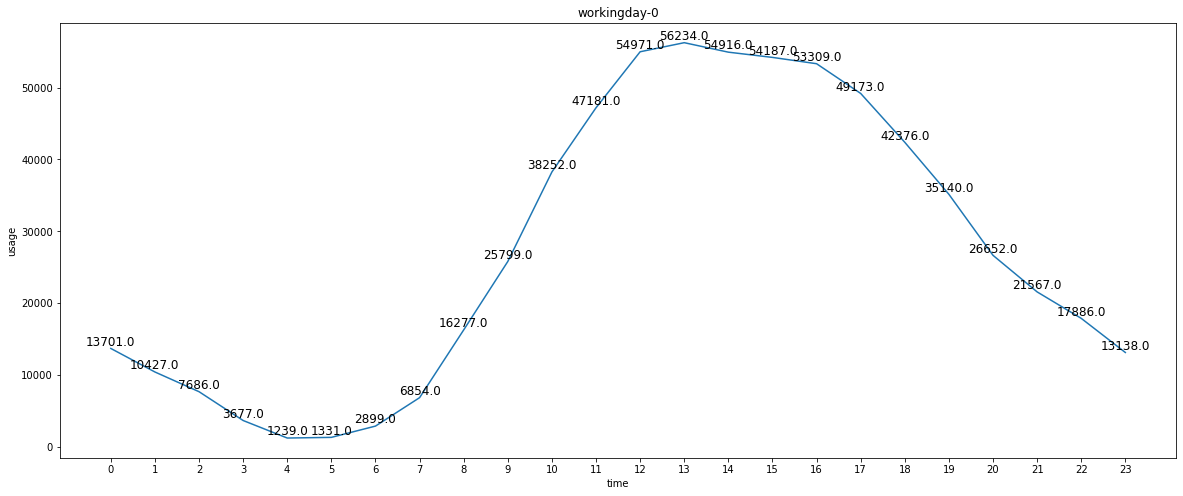

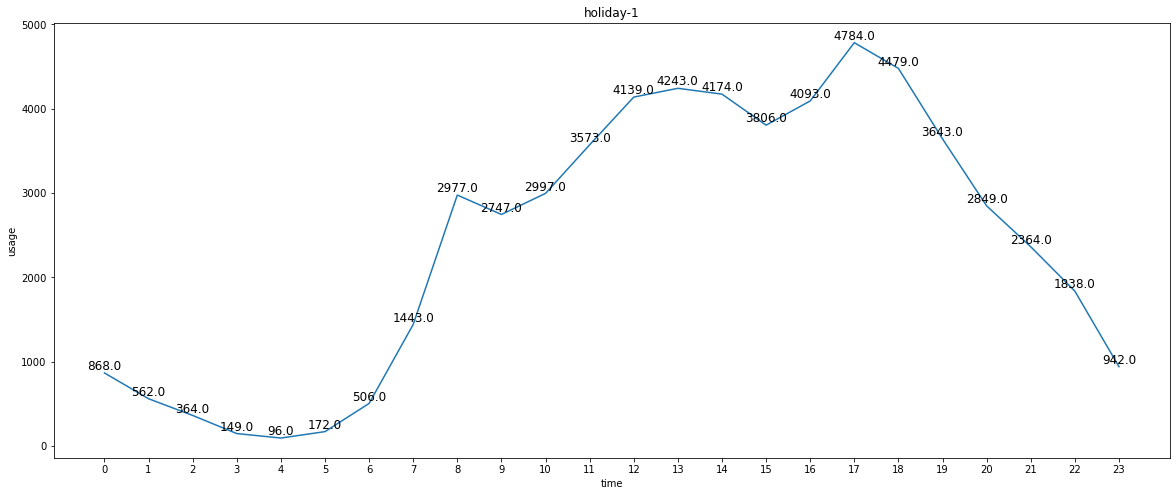

In [18]:
print(time_feature_rel("workingday",0))
print(time_feature_rel("holiday",1))

<a id="1"></a>
### <div style="text-align:left; padding:10px;color:white;margin:0;font-size:30px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b> Not Holiday == Workingday
</b></div>

None
None


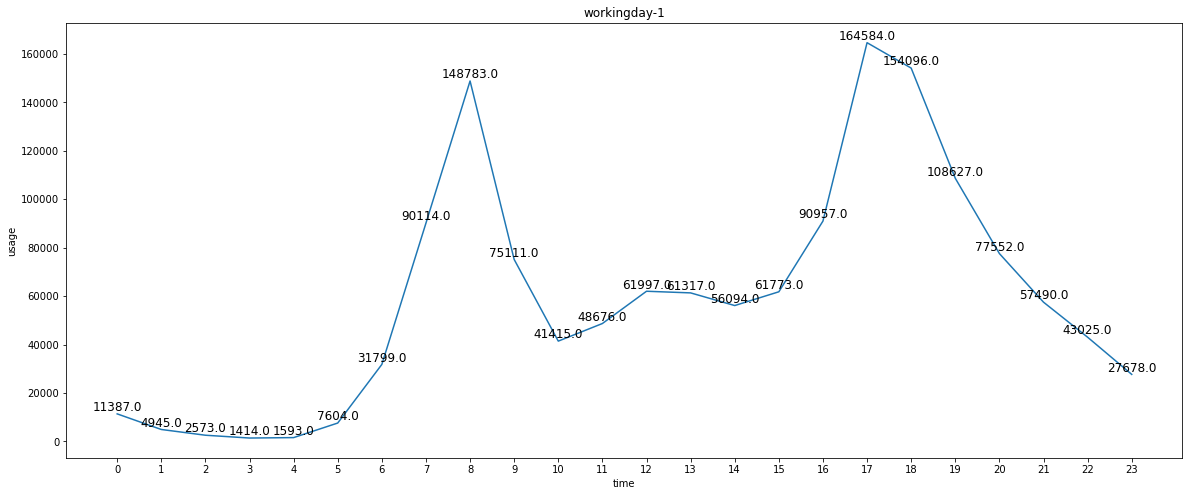

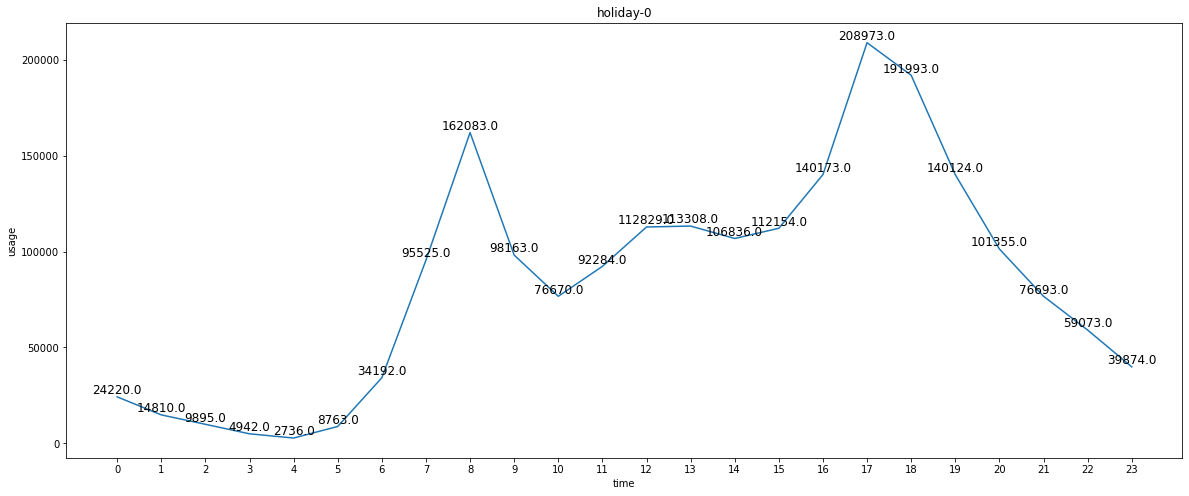

In [19]:
print(time_feature_rel("workingday",1))
print(time_feature_rel("holiday",0))

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">

<b> The visualization analysis of the data on working days and holidays shows that there is a clear difference in bicycle loan amount between working days and holidays.<br> As mentioned earlier, the amount of bicycle loans increased sharply during rush hour and rush hour on working days, but on the contrary, on holidays, it recorded a high amount of bicycle loans at 1 p.m. 

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>2.4 Humidity</b></div>

In [20]:
train["humidity"].value_counts().sort_index()

0       22
8        1
10       1
12       1
13       1
      ... 
93     205
94     324
96       1
97       1
100    148
Name: humidity, Length: 89, dtype: int64

<AxesSubplot:xlabel='humidity', ylabel='Density'>

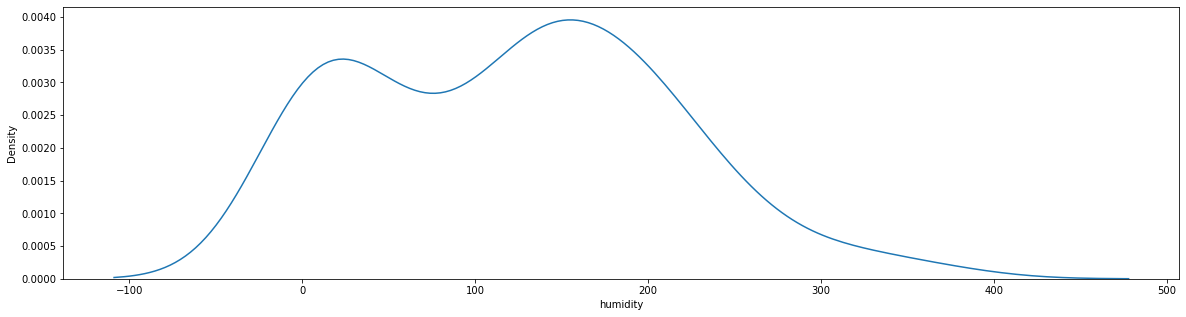

In [21]:
plt.figure(figsize=(20,5))
sns.kdeplot(train["humidity"].value_counts().sort_index())

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">

Since it is a data format of various and irregular patterns, it is necessary to add efficiency to visualization and machine learning analysis through mapping.

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>2.4.1 Mapping_Humidity
<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
<b>Data mapping Introduction</b><br>Data mapping is a process in data analysis that involves transforming data from one form or structure to another in order to better understand and analyze it. The transformed data is then often visualized to facilitate exploration and understanding of relationships and patterns. The importance of data mapping lies in its ability to reveal insights and patterns that might not be immediately apparent in raw data, and to facilitate communication of these insights to others.

In data analysis, data mapping can be used to transform and prepare data for analysis, to create visualizations that help to understand relationships between variables, and to identify trends and patterns in the data. For example, geographical data can be mapped to help understand patterns and trends in data across different regions. By visualizing the data in this way, data mapping can help to reveal hidden insights and inform decision-making.

Additionally, data mapping can be an effective tool for communicating complex data and insights to a wider audience. Visualizing data on a map can make it easier for non-technical stakeholders to understand and engage with the data, which can help to drive action and impact.

Overall, data mapping is an important step in the data analysis process, as it enables data to be transformed and visualized in a way that supports exploration, analysis, and communication of insights.

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
<b>mapping description</b><br>
Here, I divided the data into a total of <mark>10 types</mark>. Data were classified into <mark>10 units</mark>, and the average value of each unit was set as a representative value.
<br>
    <br>
I thought that setting the result value obtained through the training data would be more useful in terms of result accuracy, so I set the value according to the training data.<br>
Since the above calculation is an average value obtained based on the test data, it is a good method to set and substitute an appropriate value according to individual judgment.

<a id="1"></a>
### <div style="text-align:center; padding:10px;color:white;margin:0;font-size:30px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>Get each type's average value</b></div>

In [22]:
mapping1_10 = []
mapping10_20 = []
mapping20_30 = []
mapping30_40 = []
mapping40_50 = []
mapping50_60 = []
mapping60_70 = []
mapping70_80 = []
mapping80_90 = []
mapping90_100 = []
for i in range(len(train["humidity"].value_counts())):
    dd = []
    if 1 <= train["humidity"].value_counts().sort_index().index[i] < 10:
        for b in range(train["humidity"].value_counts().sort_index().values[i]):
            mapping1_10.append(train["humidity"].value_counts().sort_index().index[i])
    elif 10<= train["humidity"].value_counts().sort_index().index[i] < 20:
        for b in range(train["humidity"].value_counts().sort_index().values[i]):
            mapping10_20.append(train["humidity"].value_counts().sort_index().index[i])    
    elif 20<= train["humidity"].value_counts().sort_index().index[i] < 30:
        for b in range(train["humidity"].value_counts().sort_index().values[i]):
            mapping20_30.append(train["humidity"].value_counts().sort_index().index[i])
    elif 30<= train["humidity"].value_counts().sort_index().index[i] < 40:
        for b in range(train["humidity"].value_counts().sort_index().values[i]):
            mapping30_40.append(train["humidity"].value_counts().sort_index().index[i])    
    elif 40<= train["humidity"].value_counts().sort_index().index[i] < 50:
        for b in range(train["humidity"].value_counts().sort_index().values[i]):
            mapping40_50.append(train["humidity"].value_counts().sort_index().index[i])
    elif 50<= train["humidity"].value_counts().sort_index().index[i] < 60:
        for b in range(train["humidity"].value_counts().sort_index().values[i]):
            mapping50_60.append(train["humidity"].value_counts().sort_index().index[i])    
    elif 60<= train["humidity"].value_counts().sort_index().index[i] < 70:
        for b in range(train["humidity"].value_counts().sort_index().values[i]):
            mapping60_70.append(train["humidity"].value_counts().sort_index().index[i])
    elif 70<= train["humidity"].value_counts().sort_index().index[i] < 80:
        for b in range(train["humidity"].value_counts().sort_index().values[i]):
            mapping70_80.append(train["humidity"].value_counts().sort_index().index[i])
    elif 80<= train["humidity"].value_counts().sort_index().index[i] < 90:
        for b in range(train["humidity"].value_counts().sort_index().values[i]):
            mapping80_90.append(train["humidity"].value_counts().sort_index().index[i])
    elif 90<= train["humidity"].value_counts().sort_index().index[i] < 100:
        for b in range(train["humidity"].value_counts().sort_index().values[i]):
            mapping90_100.append(train["humidity"].value_counts().sort_index().index[i])

In [23]:
mapping_list_1 = [mapping1_10,mapping10_20,mapping20_30,mapping30_40,
                 mapping40_50,mapping50_60,mapping60_70,mapping70_80
                 ,mapping80_90,mapping90_100]

for i in mapping_list_1:
    print(int(np.mean(i)))

8
16
25
35
44
54
64
74
85
93


In [24]:
for i in range(len(train["humidity"].values)):
    if 1<= train["humidity"].values[i] < 10:
        train["humidity"].values[i] = 8
    elif 10<= train["humidity"].values[i] < 20:
        train["humidity"].values[i] = 16
    elif 20<= train["humidity"].values[i] < 30:
        train["humidity"].values[i] = 25
    elif 30<= train["humidity"].values[i] < 40:
        train["humidity"].values[i] = 35
    elif 40<= train["humidity"].values[i] < 50:
        train["humidity"].values[i] = 44
    elif 50<= train["humidity"].values[i] < 60:
        train["humidity"].values[i] = 54
    elif 60<= train["humidity"].values[i] < 70:
        train["humidity"].values[i] = 64
    elif 70<= train["humidity"].values[i] < 80:
        train["humidity"].values[i] = 74
    elif 80<= train["humidity"].values[i] < 90:
        train["humidity"].values[i] = 85
    elif 90<= train["humidity"].values[i] < 100:
        train["humidity"].values[i] = 93

In [25]:
train["humidity"].value_counts().sort_index()

0        22
8         1
16       45
25      364
35     1039
44     1727
54     1842
64     1748
74     1736
85     1676
93      538
100     148
Name: humidity, dtype: int64

<a id="1"></a>
### <div style="text-align:center; padding:10px;color:white;margin:0;font-size:30px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>Map test data in the same way
</b></div>

In [26]:
mapping1_10 = []
mapping10_20 = []
mapping20_30 = []
mapping30_40 = []
mapping40_50 = []
mapping50_60 = []
mapping60_70 = []
mapping70_80 = []
mapping80_90 = []
mapping90_100 = []
for i in range(len(test["humidity"].value_counts())):
    dd = []
    if 1 <= test["humidity"].value_counts().sort_index().index[i] < 10:
        for b in range(test["humidity"].value_counts().sort_index().values[i]):
            mapping1_10.append(test["humidity"].value_counts().sort_index().index[i])
    elif 10<= test["humidity"].value_counts().sort_index().index[i] < 20:
        for b in range(test["humidity"].value_counts().sort_index().values[i]):
            mapping10_20.append(test["humidity"].value_counts().sort_index().index[i])    
    elif 20<= test["humidity"].value_counts().sort_index().index[i] < 30:
        for b in range(test["humidity"].value_counts().sort_index().values[i]):
            mapping20_30.append(test["humidity"].value_counts().sort_index().index[i])
    elif 30<= test["humidity"].value_counts().sort_index().index[i] < 40:
        for b in range(test["humidity"].value_counts().sort_index().values[i]):
            mapping30_40.append(test["humidity"].value_counts().sort_index().index[i])    
    elif 40<= test["humidity"].value_counts().sort_index().index[i] < 50:
        for b in range(test["humidity"].value_counts().sort_index().values[i]):
            mapping40_50.append(test["humidity"].value_counts().sort_index().index[i])
    elif 50<= test["humidity"].value_counts().sort_index().index[i] < 60:
        for b in range(test["humidity"].value_counts().sort_index().values[i]):
            mapping50_60.append(test["humidity"].value_counts().sort_index().index[i])    
    elif 60<= test["humidity"].value_counts().sort_index().index[i] < 70:
        for b in range(test["humidity"].value_counts().sort_index().values[i]):
            mapping60_70.append(test["humidity"].value_counts().sort_index().index[i])
    elif 70<= test["humidity"].value_counts().sort_index().index[i] < 80:
        for b in range(test["humidity"].value_counts().sort_index().values[i]):
            mapping70_80.append(test["humidity"].value_counts().sort_index().index[i])
    elif 80<= test["humidity"].value_counts().sort_index().index[i] < 90:
        for b in range(test["humidity"].value_counts().sort_index().values[i]):
            mapping80_90.append(test["humidity"].value_counts().sort_index().index[i])
    elif 90<= test["humidity"].value_counts().sort_index().index[i] < 100:
        for b in range(test["humidity"].value_counts().sort_index().values[i]):
            mapping90_100.append(test["humidity"].value_counts().sort_index().index[i])

mapping_list_1 = [mapping10_20,mapping20_30,mapping30_40,
                 mapping40_50,mapping50_60,mapping60_70,mapping70_80
                 ,mapping80_90,mapping90_100]

for i in mapping_list_1:
#     print(i)
    print(int(np.mean(i)))

17
25
35
44
54
64
74
85
93


<div style="text-align:left;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
There is no value [1,10] in test data. So I just print [10,100] values.<br>

In [27]:
for i in range(len(test["humidity"].values)):
    if 10<= test["humidity"].values[i] < 20:
        test["humidity"].values[i] = 16
    elif 20<= test["humidity"].values[i] < 30:
        test["humidity"].values[i] = 25
    elif 30<= test["humidity"].values[i] < 40:
        test["humidity"].values[i] = 35
    elif 40<= test["humidity"].values[i] < 50:
        test["humidity"].values[i] = 44
    elif 50<= test["humidity"].values[i] < 60:
        test["humidity"].values[i] = 54
    elif 60<= test["humidity"].values[i] < 70:
        test["humidity"].values[i] = 64
    elif 70<= test["humidity"].values[i] < 80:
        test["humidity"].values[i] = 74
    elif 80<= test["humidity"].values[i] < 90:
        test["humidity"].values[i] = 85
    elif 90<= test["humidity"].values[i] < 100:
        test["humidity"].values[i] = 93

<BarContainer object of 12 artists>

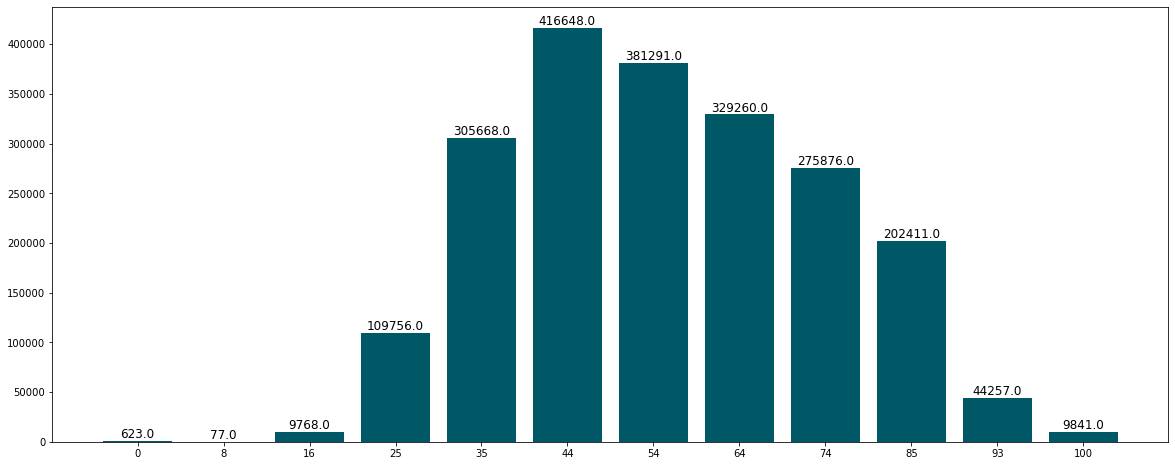

In [28]:
y = (train[train["humidity"]==0]["count"].sum(),
train[train["humidity"]==8]["count"].sum(),
train[train["humidity"]==16]["count"].sum(),
train[train["humidity"]==25]["count"].sum(),
train[train["humidity"]==35]["count"].sum(),
train[train["humidity"]==44]["count"].sum(),
train[train["humidity"]==54]["count"].sum(),
train[train["humidity"]==64]["count"].sum(),
train[train["humidity"]==74]["count"].sum(),
train[train["humidity"]==85]["count"].sum(),
train[train["humidity"]==93]["count"].sum(),
train[train["humidity"]==100]["count"].sum())

x = ["0","8","16","25","35","44","54","64","74","85","93","100"]
plt.figure(figsize=(20,8))
for i in range(len(x)):
    height = y[i]
    plt.text(x[i], height + 1.9, '%.1f' %height, ha='center', va='bottom', size = 12)


plt.bar(x,y,color = '#005766')

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
<b> When the average humidity is about 44, it can be seen that the bicycle loan is the highest.

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>2.5 WindSpeed</b></div>

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>2.5.1 Mapping_WindSpeed</b></div>

### maps wind speed in the same way as humidity.

In [29]:
train["windspeed"].value_counts().sort_index()

0.0000     1313
6.0032      872
7.0015     1034
8.9981     1120
11.0014    1057
12.9980    1042
15.0013     961
16.9979     824
19.0012     676
19.9995     492
22.0028     372
23.9994     274
26.0027     235
27.9993     187
30.0026     111
31.0009      89
32.9975      80
35.0008      58
36.9974      22
39.0007      27
40.9973      11
43.0006      12
43.9989       8
46.0022       3
47.9988       2
50.0021       1
51.9987       1
56.9969       2
Name: windspeed, dtype: int64

In [30]:
mapping1_10 = []
mapping10_20 = []
mapping20_30 = []
mapping30_40 = []
mapping40_50 = []
mapping50_60 = []

for i in range(len(train["windspeed"].value_counts())):
    dd = []
    if 1 <= train["windspeed"].value_counts().sort_index().index[i] < 10:
        for b in range(train["windspeed"].value_counts().sort_index().values[i]):
            mapping1_10.append(train["windspeed"].value_counts().sort_index().index[i])
    elif 10<= train["windspeed"].value_counts().sort_index().index[i] < 20:
        for b in range(train["windspeed"].value_counts().sort_index().values[i]):
            mapping10_20.append(train["windspeed"].value_counts().sort_index().index[i])    
    elif 20<= train["windspeed"].value_counts().sort_index().index[i] < 30:
        for b in range(train["windspeed"].value_counts().sort_index().values[i]):
            mapping20_30.append(train["windspeed"].value_counts().sort_index().index[i])
    elif 30<= train["windspeed"].value_counts().sort_index().index[i] < 40:
        for b in range(train["windspeed"].value_counts().sort_index().values[i]):
            mapping30_40.append(train["windspeed"].value_counts().sort_index().index[i])    
    elif 40<= train["windspeed"].value_counts().sort_index().index[i] < 50:
        for b in range(train["windspeed"].value_counts().sort_index().values[i]):
            mapping40_50.append(train["windspeed"].value_counts().sort_index().index[i])
    elif 50<= train["windspeed"].value_counts().sort_index().index[i] < 60:
        for b in range(train["windspeed"].value_counts().sort_index().values[i]):
            mapping50_60.append(train["windspeed"].value_counts().sort_index().index[i])    


mapping_list_1 = [mapping1_10,mapping10_20,mapping20_30,mapping30_40,
                 mapping40_50,mapping50_60]

for i in mapping_list_1:
    print(int(np.mean(i)))

7
15
24
32
43
53


In [31]:
mapping1_10 = []
mapping10_20 = []
mapping20_30 = []
mapping30_40 = []
mapping40_50 = []
mapping50_60 = []

for i in range(len(test["windspeed"].value_counts())):
    dd = []
    if 1 <= test["windspeed"].value_counts().sort_index().index[i] < 10:
        for b in range(test["windspeed"].value_counts().sort_index().values[i]):
            mapping1_10.append(test["windspeed"].value_counts().sort_index().index[i])
    elif 10<= test["windspeed"].value_counts().sort_index().index[i] < 20:
        for b in range(test["windspeed"].value_counts().sort_index().values[i]):
            mapping10_20.append(test["windspeed"].value_counts().sort_index().index[i])    
    elif 20<= test["windspeed"].value_counts().sort_index().index[i] < 30:
        for b in range(test["windspeed"].value_counts().sort_index().values[i]):
            mapping20_30.append(test["windspeed"].value_counts().sort_index().index[i])
    elif 30<= test["windspeed"].value_counts().sort_index().index[i] < 40:
        for b in range(test["windspeed"].value_counts().sort_index().values[i]):
            mapping30_40.append(test["windspeed"].value_counts().sort_index().index[i])    
    elif 40<= test["windspeed"].value_counts().sort_index().index[i] < 50:
        for b in range(test["windspeed"].value_counts().sort_index().values[i]):
            mapping40_50.append(test["windspeed"].value_counts().sort_index().index[i])
    elif 50<= test["windspeed"].value_counts().sort_index().index[i] < 60:
        for b in range(test["windspeed"].value_counts().sort_index().values[i]):
            mapping50_60.append(test["windspeed"].value_counts().sort_index().index[i])    


mapping_list_1 = [mapping1_10,mapping10_20,mapping20_30,mapping30_40,
                 mapping40_50,mapping50_60]

for i in mapping_list_1:
    print((np.mean(i)))

7.3902336944127685
15.076815148448047
24.40067108792847
32.59405981308411
42.20894210526316
53.501175


In [32]:

for i in range(len(train["windspeed"].values)):
    if 1<= train["windspeed"].values[i] < 10:
        train["windspeed"].values[i] = 7
    elif 10<= train["windspeed"].values[i] < 20:
        train["windspeed"].values[i] = 15
    elif 20<= train["windspeed"].values[i] < 30:
        train["windspeed"].values[i] = 24
    elif 30<= train["windspeed"].values[i] < 40:
        train["windspeed"].values[i] = 32
    elif 40<= train["windspeed"].values[i] < 50:
        train["windspeed"].values[i] = 43
    elif 50<= train["windspeed"].values[i] < 60:
        train["windspeed"].values[i] = 54

In [33]:
for i in range(len(test["windspeed"].values)):
    if 1<= test["windspeed"].values[i] < 10:
        test["windspeed"].values[i] = 7
    elif 10<= test["windspeed"].values[i] < 20:
        test["windspeed"].values[i] = 15
    elif 20<= test["windspeed"].values[i] < 30:
        test["windspeed"].values[i] = 24
    elif 30<= test["windspeed"].values[i] < 40:
        test["windspeed"].values[i] = 32
    elif 40<= test["windspeed"].values[i] < 50:
        test["windspeed"].values[i] = 43
    elif 50<= test["windspeed"].values[i] < 60:
        test["windspeed"].values[i] = 54

In [34]:
train["windspeed"].value_counts().sort_index()

0.0     1313
7.0     3026
15.0    5052
24.0    1068
32.0     387
43.0      36
54.0       4
Name: windspeed, dtype: int64

In [35]:
test["windspeed"].value_counts().sort_index()

0.0      867
7.0     1754
15.0    2964
24.0     671
32.0     214
43.0      19
54.0       4
Name: windspeed, dtype: int64

<BarContainer object of 7 artists>

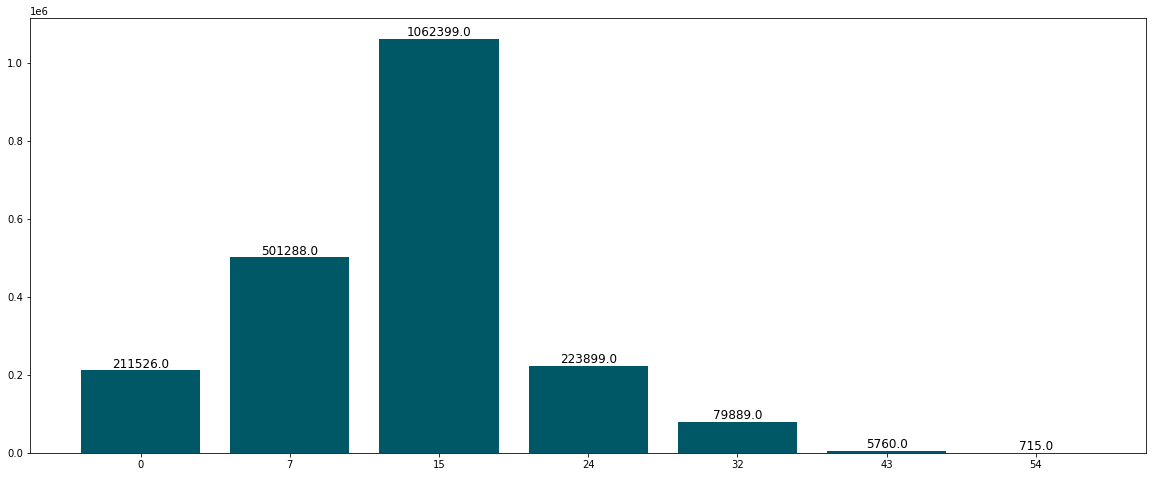

In [36]:
y = (train[train["windspeed"]==0.0]["count"].sum(),
train[train["windspeed"]==7.0]["count"].sum(),
train[train["windspeed"]==15.0]["count"].sum(),
train[train["windspeed"]==24.0]["count"].sum(),
train[train["windspeed"]==32.0]["count"].sum(),
train[train["windspeed"]==43.0]["count"].sum(),
train[train["windspeed"]==54.0]["count"].sum())


x = ["0","7","15","24","32","43","54"]
plt.figure(figsize=(20,8))
for i in range(len(x)):
    height = y[i]
    plt.text(x[i], height + 1.9, '%.1f' %height, ha='center', va='bottom', size = 12)


plt.bar(x,y,color = '#005766')

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
<b> When the wind speed averaged 15.098, the bicycle loan was the highest.

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>2.6 HeatMap
</b></div>

In [37]:
heatmap_data = train.drop("datetime",axis=1)

<AxesSubplot:title={'center':'Person Correlation of Features'}>

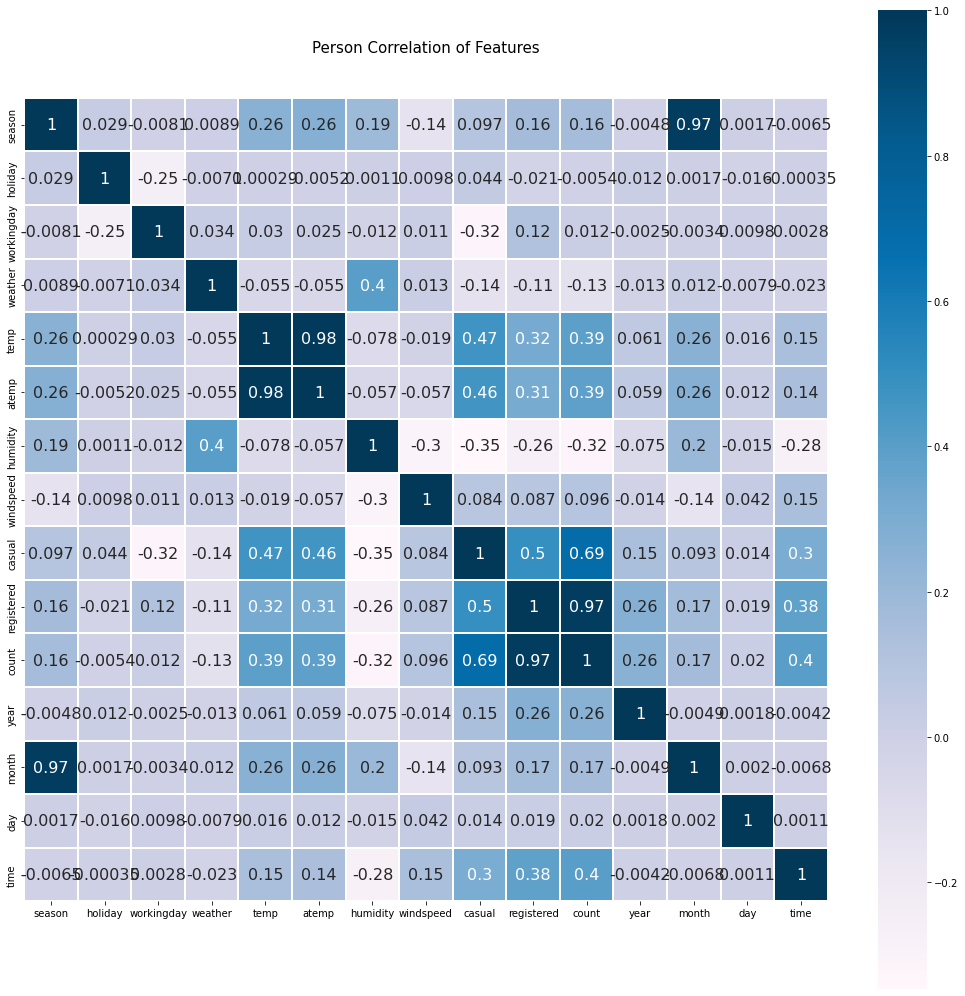

In [38]:
colormap = plt.cm.PuBu
plt.figure(figsize=(18, 18))
plt.title("Person Correlation of Features", y = 1.05, size = 15)
sns.heatmap(heatmap_data.astype(float).corr(), linewidths = 0.1, vmax = 1.0,
           square = True, cmap = colormap, linecolor = "white", annot = True, annot_kws = {"size" : 16})

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>Preparing Test Set</b></div>

In [39]:
train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,year,month,day,time
0,2011-01-01 00:00:00,1,0,0,1,9.84,14.395,85,0.0,3,13,16,2011,1,1,0
1,2011-01-01 01:00:00,1,0,0,1,9.02,13.635,85,0.0,8,32,40,2011,1,1,1
2,2011-01-01 02:00:00,1,0,0,1,9.02,13.635,85,0.0,5,27,32,2011,1,1,2
3,2011-01-01 03:00:00,1,0,0,1,9.84,14.395,74,0.0,3,10,13,2011,1,1,3
4,2011-01-01 04:00:00,1,0,0,1,9.84,14.395,74,0.0,0,1,1,2011,1,1,4


In [40]:
features = ["season","holiday","workingday","weather","temp","atemp","humidity","windspeed","year","month","day","time"]

In [41]:
x_train = train[features]
x_test = test[features]
y_train = train["count"]

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>3. Deep Learning - Regression Model</b></div>

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
<b> Deep learning regression models are a type of artificial neural network used for predicting continuous values, such as stock prices, housing prices, or temperature. They consist of multiple layers of interconnected nodes that process input data and make predictions based on learned relationships between inputs and outputs. These models are trained on large amounts of data using gradient descent optimization, which adjusts the weights of the network to minimize prediction error. The strength of deep learning regression models lies in their ability to learn complex, non-linear relationships from data, making them a powerful tool for a variety of applications.<br>
    <br>
    In this sessiong, I should predict the count of sharing demand. So, It would be more useful to use regression model to get more exact predict result.

In [42]:
# Create the model
model = tf.keras.Sequential()
model.add(tf.keras.layers.Dense(units=32, activation='relu'))
model.add(tf.keras.layers.Dense(units=64, activation='relu'))
model.add(tf.keras.layers.Dense(units=128, activation='relu'))
model.add(tf.keras.layers.Dense(units=256, activation='relu'))
model.add(tf.keras.layers.Dense(units=64, activation='relu'))
model.add(tf.keras.layers.Dense(units=32, activation='relu'))
model.add(tf.keras.layers.Dense(units=16, activation='relu'))
model.add(tf.keras.layers.Dense(units=1,activation="linear"))

# # Compile the model with a mean squared error loss function
# model.compile(optimizer='adam', loss='mean_squared_error')

# Compile the model with a mean squared error loss function and L2 regularization
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

# Train the model on the train data
# early_stop = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10)
history = model.fit(x_train, y_train, epochs=200, verbose = 0)

# Predict the values of y for the test data
y_pred = model.predict(x_test)
print("Predicted y values:", y_pred)

# # Evaluate the model's performance on the test data
# test_loss = model.evaluate(x_test)
# print("Test loss:", test_loss)

Predicted y values: [[ 20.02573 ]
 [ 12.91217 ]
 [  8.663783]
 ...
 [125.87741 ]
 [104.14744 ]
 [106.07634 ]]


In [43]:
deep_learning_prediction = np.array(y_pred)

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>4. MachineLearning
</b></div>

In [44]:
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
from catboost import CatBoostRegressor
import xgboost as xgb

k_fold = KFold(n_splits = 10, shuffle = True , random_state = 0)

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>XGBoost, Catboost, RandomForest Regressor default score comparison
</b></div>

In [45]:
cbr = CatBoostRegressor(verbose=0)
xgbr = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=100, max_depth=5)
rfr = RandomForestRegressor()

model_list = [cbr,xgbr,rfr]
model_score = []
for model in model_list:
    model.fit(x_train,y_train)
    model_score.append(model.score(x_train,y_train))
model_score

[0.9697614370923578, 0.96532940761897, 0.9924596532005042]

<BarContainer object of 3 artists>

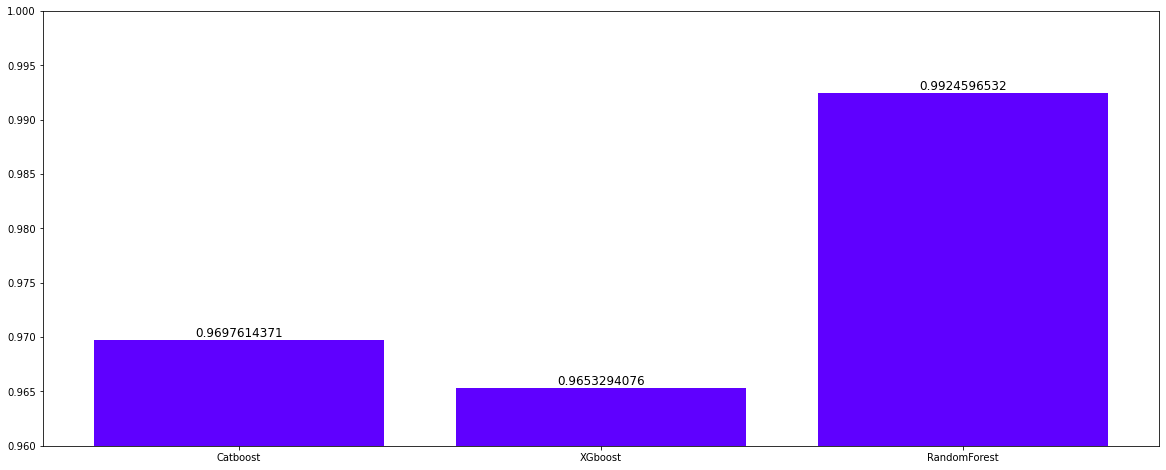

In [46]:
model_name = ["Catboost","XGboost","RandomForest"]
plt.figure(figsize=(20,8))
x = model_name
y = model_score
for i in range(len(x)):
    height = y[i]
    plt.text(x[i], height, '%.10f' %height, ha='center', va='bottom', size = 12)
plt.ylim(0.96,1)
plt.bar(x,y,color='#5F00FF')

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
<mark>RandomForestRegressor</mark> showed better performance on this data.

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>RandomForestRegressor
</b></div>

relation_square :  0.988809781937634


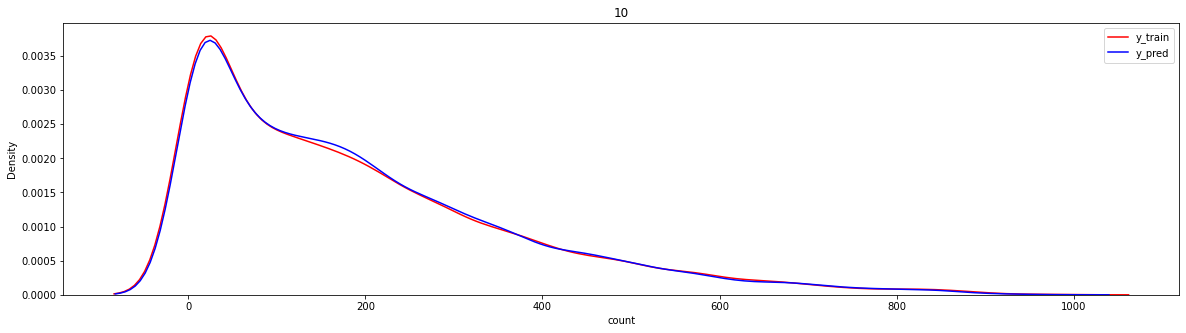

relation_square :  0.9907357329088907


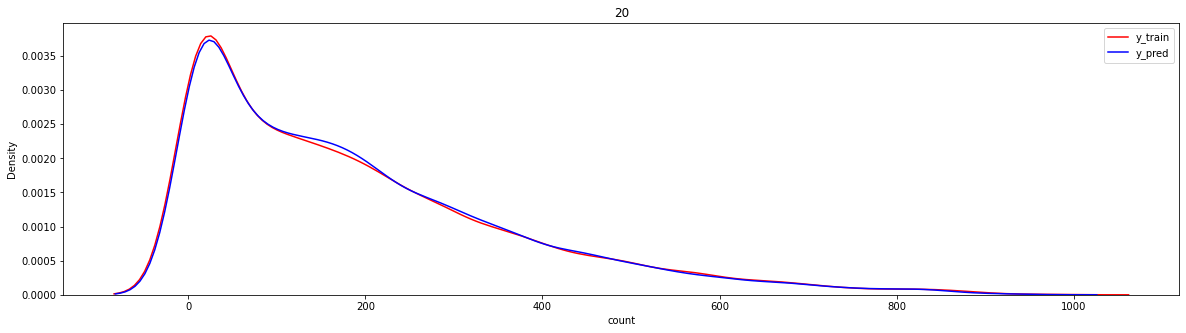

relation_square :  0.9915356241571875


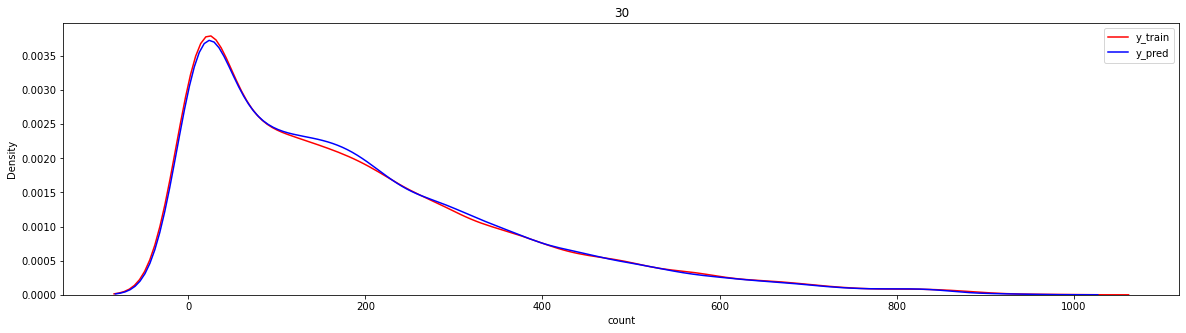

relation_square :  0.9917807112008029


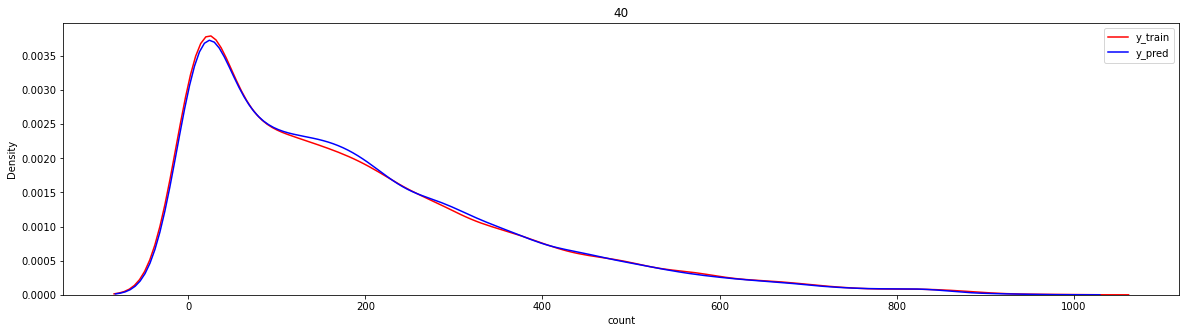

relation_square :  0.9924337204221625


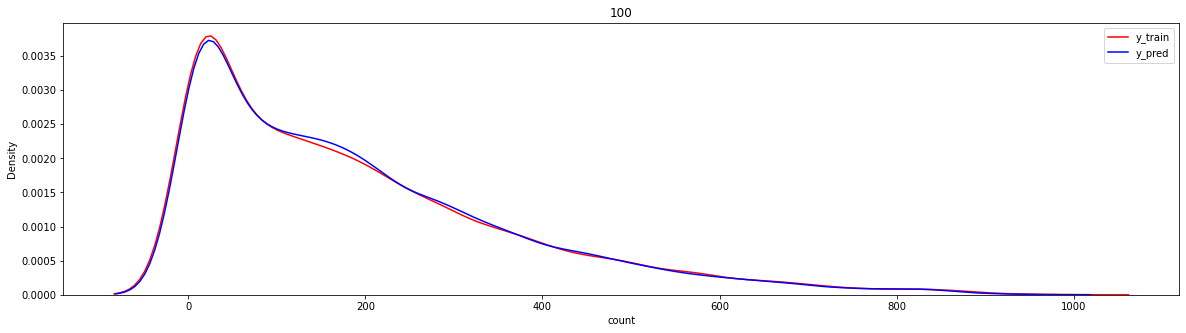

relation_square :  0.9926364536827665


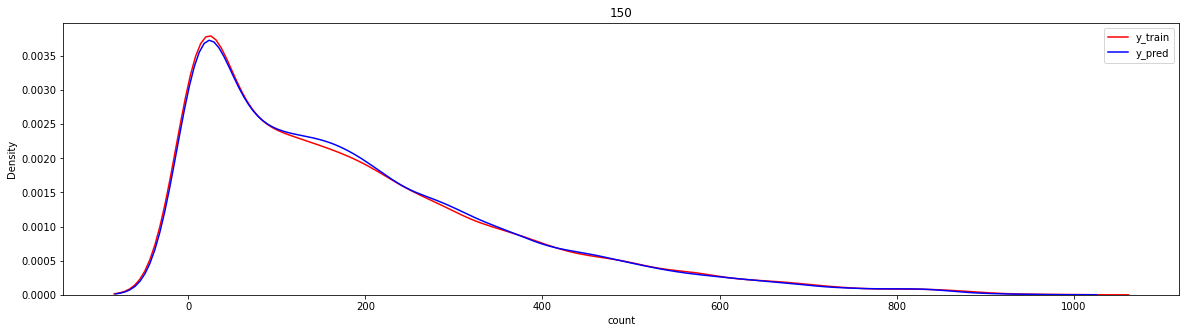

relation_square :  0.9926917856915903


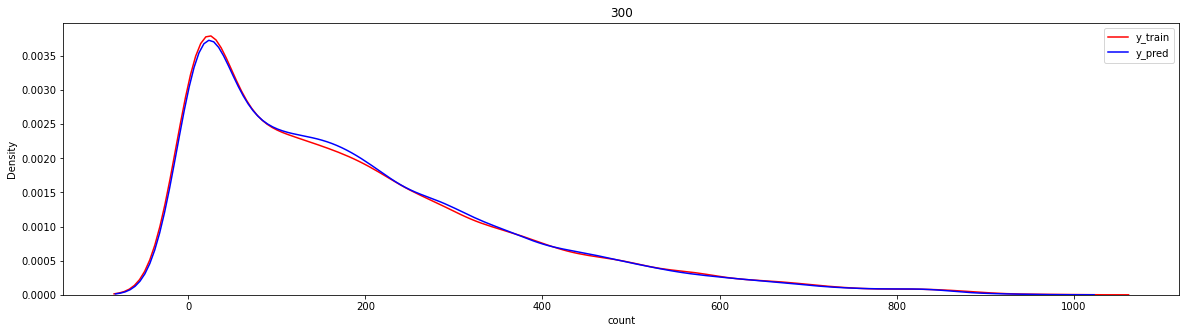

In [47]:
from sklearn.ensemble import RandomForestRegressor
# Check the result according to "n_estimators".
for i in (10, 20, 30, 40, 100, 150,300):
    model = RandomForestRegressor(n_estimators= i,n_jobs= -1, random_state = 15)
    model.fit(x_train,y_train)
    # The higher the "n_estimators" value, the higher the accuracy, 
    # but the more computational it takes for the computer to calculate and derive results. 
    # I set the value to 300 appropriately.

    relation_square = model.score(x_train, y_train)
    print('relation_square : ', relation_square)
    plt.figure(figsize=(20,5))
    y_p = model.predict(x_train)
    ax1 = sns.kdeplot(y_train,label = 'y_train',color="red")
    ax2 = sns.kdeplot(y_p,label = 'y_pred',color="blue")
    
    plt.title(i)
    plt.legend()
    plt.show()

In [48]:
model = RandomForestRegressor(n_estimators=300, n_jobs = -1 , random_state = 0)
model.fit(x_train, y_train)

predictions = model.predict(x_test)
predictions

array([ 14.24333333,   6.08333333,   5.56666667, ..., 146.95      ,
       118.02333333,  73.35      ])

In [49]:
machine_learning_prediction = predictions

In [50]:
machine_learning_prediction

array([ 14.24333333,   6.08333333,   5.56666667, ..., 146.95      ,
       118.02333333,  73.35      ])

In [51]:
deep_learning_prediction1 = []
for i in range(len(deep_learning_prediction)):
    deep_learning_prediction1.append(deep_learning_prediction[i][0])
deep_learning_prediction1 = np.array(deep_learning_prediction1)
deep_learning_prediction1

array([ 20.02573 ,  12.91217 ,   8.663783, ..., 125.87741 , 104.14744 ,
       106.07634 ], dtype=float32)

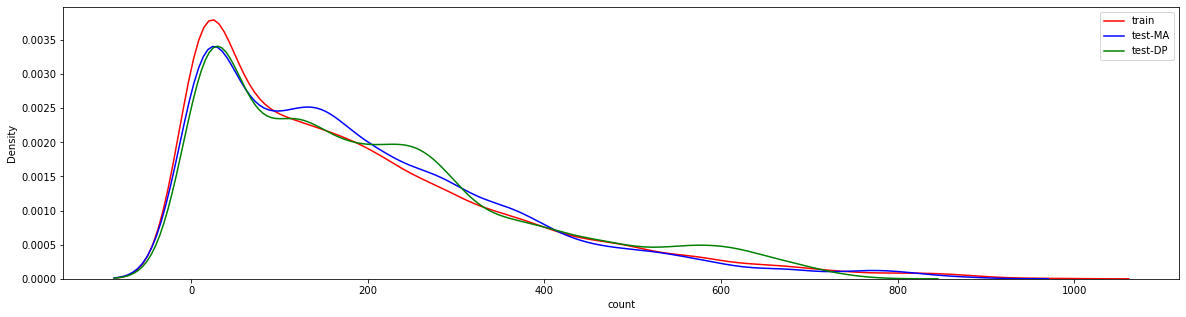

In [52]:
plt.figure(figsize=(20,5))
ax1 = sns.kdeplot(y_train, label = 'train',color="red")
ax2 = sns.kdeplot(machine_learning_prediction, label = 'test-MA',color="blue")
ax3 = sns.kdeplot(deep_learning_prediction1, label = 'test-DP',color="green")

plt.legend()
plt.show()

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>Ensemble</b></div>

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
<b> Through the above graph, graphs of predictions through machine learning and predictions through deep learning often cross each other. It has prediction results of opposite patterns. To compensate for this, we try to derive a new prediction value by obtaining the average value of the two values.

In [53]:
print(len(deep_learning_prediction))
print(len(machine_learning_prediction))
print(len(y_train))

6493
6493
10886


In [54]:
i = 100
print(deep_learning_prediction[i][0],machine_learning_prediction[i],y_train[i])

130.08794 79.82 115


In [55]:
import math
final_pred = []
for i in range(6493):
    final_pred.append((deep_learning_prediction[i][0]+machine_learning_prediction[i])/2)

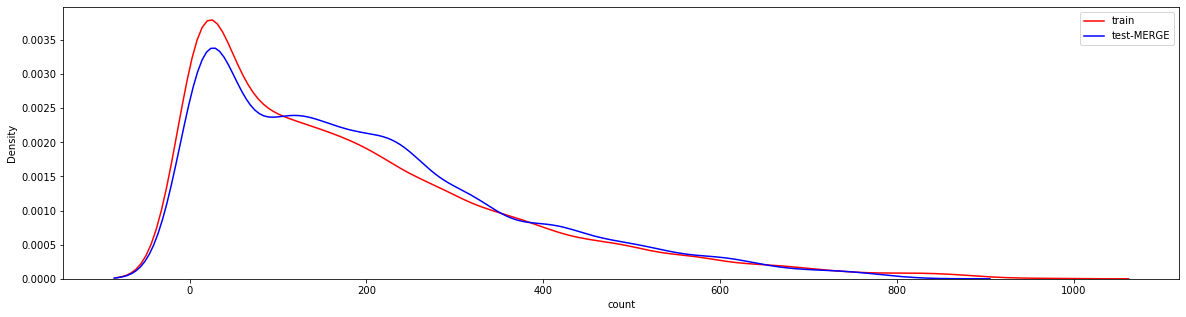

In [56]:
plt.figure(figsize=(20,5))
ax1 = sns.kdeplot(y_train, label = 'train',color="red")
ax2 = sns.kdeplot(final_pred, label = 'test-MERGE',color="blue")

plt.legend()
plt.show()

<a id="1"></a>
# <div style="text-align:center; padding:20px;color:white;margin:0;font-size:35px;font-family:Serif;display:fill;border-radius:5px;background-color:#22741C;overflow:hidden"><b>4. Submission</b></div>


In [57]:
submission = pd.read_csv("/kaggle/input/bike-sharing-demand/sampleSubmission.csv")

<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
As a result, we obtained a total of three kinds of predictions as a result of <br>
<b>deep learning prediction, <br>
machine learning prediction, <br>
and average prediction result of both predictions.
    
</b> So in this session, we can choose any data what I want.<br>
I want use merge prediction. so define submission value is "final_pred"

In [58]:
submission["count"] = final_pred
# In this session, I use merge prediction which is the average predict between ML and DL.
# If you want submit machine learning prediction, then use "machine_learning_prediction"
# or if you want submit deep learning prediction, then use "deep_learning_prediction"

In [59]:
submission

,datetime,count
0,2011-01-20 00:00:00,17.134532
1,2011-01-20 01:00:00,9.497752
2,2011-01-20 02:00:00,7.115225
3,2011-01-20 03:00:00,5.218034
4,2011-01-20 04:00:00,4.102686
...,...,...
6488,2012-12-31 19:00:00,246.883870
6489,2012-12-31 20:00:00,176.052773
6490,2012-12-31 21:00:00,136.413705
6491,2012-12-31 22:00:00,111.085386


In [60]:
submission.to_csv("submission.csv",index=False)

In [61]:
submission = pd.read_csv("submission.csv")
submission.head()

,datetime,count
0,2011-01-20 00:00:00,17.134532
1,2011-01-20 01:00:00,9.497752
2,2011-01-20 02:00:00,7.115225
3,2011-01-20 03:00:00,5.218034
4,2011-01-20 04:00:00,4.102686


<div style="text-align:center;font-family:Comic Sans;background-color:#CEFBC9; padding:30px; font-size:17px">
<b> Submission Score:<br>
    Merge Pred: </b>0.46969<br>
    <b>Machine Pred: </b>0.48616<br>
    <b>Deep Pred: </b>0.55899<br>

<AxesSubplot:title={'center':'Score Comparison Graph'}, xlabel='Pred_Type', ylabel='Pred_Score'>

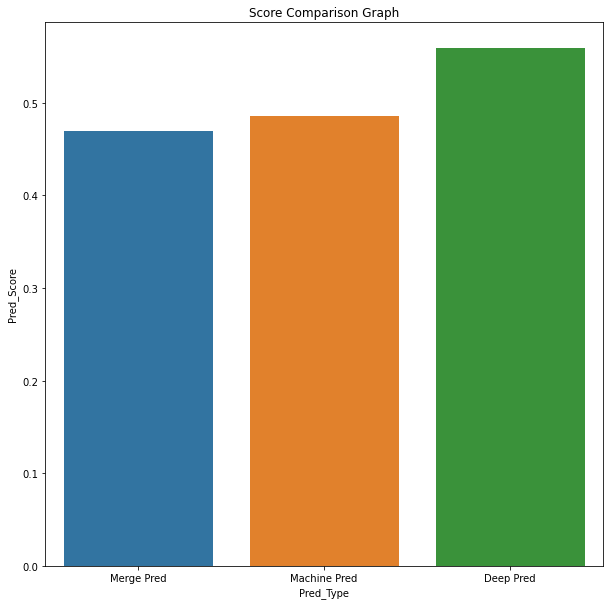

In [62]:
Score_result = pd.DataFrame()
pred_type = ["Merge Pred","Machine Pred","Deep Pred"]
pred_score = [0.46969,0.48616,0.55899]
Score_result.insert(0,"Pred_Type",pred_type)
Score_result.insert(0,"Pred_Score",pred_score)
# Score_result.set_index("Pred_Type",pred_type)
# Score_result["Pred_Score"]
plt.figure(figsize=(10,10))
plt.title("Score Comparison Graph")
sns.barplot(data = Score_result, x = Score_result["Pred_Type"],y = Score_result["Pred_Score"])

#### <div style='text-align:center; font-family:arial'> 🙇🏻‍♂️Thanks For Watching!<br></div>